# Analyzing ClinVar variants

In [2]:
import os
import polars as pl
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
# import concurrent.futures

aa_single_to_three = {
    'A': 'Ala',  # Alanine
    'R': 'Arg',  # Arginine
    'N': 'Asn',  # Asparagine
    'D': 'Asp',  # Aspartic acid
    'C': 'Cys',  # Cysteine
    'Q': 'Gln',  # Glutamine
    'E': 'Glu',  # Glutamic acid
    'G': 'Gly',  # Glycine
    'H': 'His',  # Histidine
    'I': 'Ile',  # Isoleucine
    'L': 'Leu',  # Leucine
    'K': 'Lys',  # Lysine
    'M': 'Met',  # Methionine
    'F': 'Phe',  # Phenylalanine
    'P': 'Pro',  # Proline
    'S': 'Ser',  # Serine
    'T': 'Thr',  # Threonine
    'W': 'Trp',  # Tryptophan
    'Y': 'Tyr',  # Tyrosine
    'V': 'Val'   # Valine
}

## Loading the dbnsfp snps

In [35]:
df_clinvar = pl.scan_parquet(f"../3_outputs/processed_data/dbnsfp/dbNSFP5.0a_variant.clin_var_re-annot_dedup_variants.parquet")
# df_clinvar.collect()
# df_clinvar.filter(pl.col("aaalt").str.len_chars() == 1).collect()

In [36]:
# Once you’re happy with the behavior on the subset,
# you can apply it to the entire lazy DataFrame.
# Assume ldf is your lazy DataFrame.
# Randomly sample 1000 rows from the exploded DataFrame
# df_clinvar_sampled = df_clinvar_exploded.collect().sample(n=1000)

variant_annot = [
    "hg19_chr","genename","Ensembl_geneid","Ensembl_proteinid",
    "Uniprot_acc","Uniprot_entry",
    "aapos","aaref","aaref_3","aaalt","aaalt_3",#"aa_change",
    "Ensembl_transcriptid","hg19_pos(1-based)","HGVSc_snpEff","HGVSp_snpEff",
    "HGVSc_VEP","HGVSp_VEP",
]
predictor_algos = [
    "PROVEAN_score","PROVEAN_converted_rankscore","PROVEAN_pred",
    "ESM1b_score","ESM1b_rankscore","ESM1b_pred",
    "AlphaMissense_score","AlphaMissense_rankscore","AlphaMissense_pred"
] + [col for col in df_clinvar.collect_schema().names() if "clinvar" in col]

## AI-predictor scores distribution

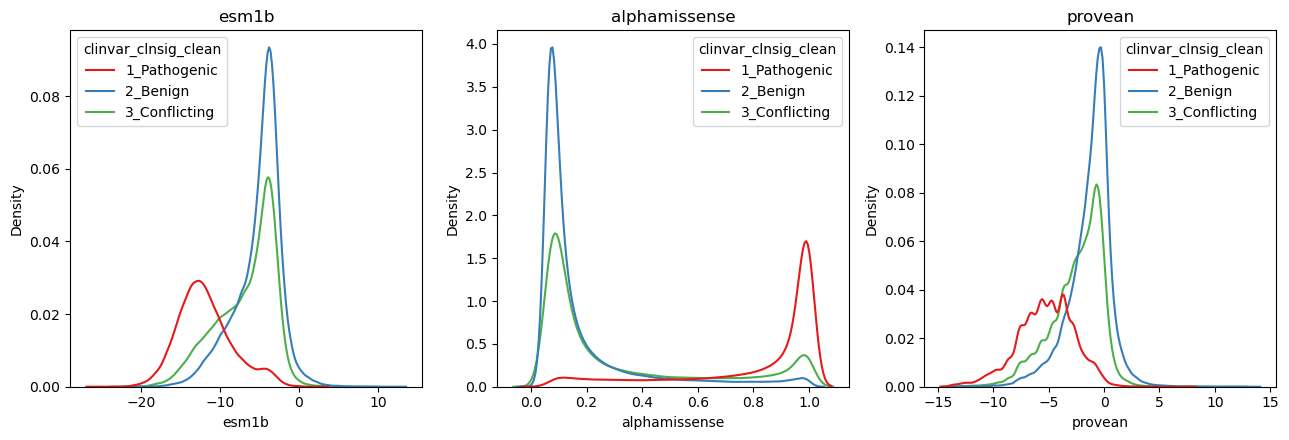

In [37]:
df_clinvar_sampled_plots = df_clinvar.select(
    pl.col("ESM1b_score","AlphaMissense_score","PROVEAN_score","clinvar_clnsig_clean")
).with_columns(
    pl.col("ESM1b_score").replace(".", None).cast(pl.Float64).alias("esm1b"),
    pl.col("AlphaMissense_score").replace(".", None).cast(pl.Float64).alias("alphamissense"),
    pl.col("PROVEAN_score").replace(".", None).cast(pl.Float64).alias("provean")
).filter((pl.col("clinvar_clnsig_clean")!="4_VUS")&(pl.col("clinvar_clnsig_clean")!="5_Others")).collect()

# Define variables to plot
variables = ["esm1b", "alphamissense", "provean"]

# Create a FacetGrid for multiple subplots
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5)) ## , sharey=True
hue_order = sorted(df_clinvar_sampled_plots["clinvar_clnsig_clean"].drop_nulls().unique().to_list())
# Loop through variables and create subplots
for ax, var in zip(axes, variables):
    sns.kdeplot(
        data=df_clinvar_sampled_plots,
        x=var,
        hue="clinvar_clnsig_clean",
        hue_order=hue_order,
        # kde=True,
        ax=ax,
        palette="Set1"
    )
    ax.set_title(var)
    
plt.tight_layout()
plt.show()

## AI-predictor scores across structure

In [4]:
df_clinvar_scores = pl.scan_parquet(f"../3_outputs/processed_data/dbnsfp/dbNSFP5.0a_variant.clin_var_dedup_plddt_rsa.parquet")
df_clinvar_scores = df_clinvar_scores.with_columns(
    pl.col("plddt").cast(pl.Float32).alias("plddt_f32"),
    pl.col("rsa").cast(pl.Float32).alias("rsa_f32"),
)

In [5]:
df_clinvar_scores.filter(~pl.col("plddt_f32").is_nan()).collect()

#chr,pos(1-based),ref,alt,aaref,aaalt,rs_dbSNP,hg19_chr,hg19_pos(1-based),hg18_chr,hg18_pos(1-based),aapos,genename,Ensembl_geneid,Ensembl_transcriptid,Ensembl_proteinid,Uniprot_acc,Uniprot_entry,HGVSc_snpEff,HGVSp_snpEff,HGVSc_VEP,HGVSp_VEP,APPRIS,GENCODE_basic,TSL,VEP_canonical,MANE,cds_strand,refcodon,codonpos,codon_degeneracy,Ancestral_allele,AltaiNeandertal,Denisova,VindijiaNeandertal,ChagyrskayaNeandertal,SIFT_score,…,Origin,OriginSimple,Assembly,ChromosomeAccession,Chromosome,Start,Stop,Cytogenetic,ReviewStatus,NumberSubmitters,Guidelines,TestedInGTR,OtherIDs,SubmitterCategories,VariationID,PositionVCF,ReferenceAlleleVCF,AlternateAlleleVCF,SomaticClinicalImpact,SomaticClinicalImpactLastEvaluated,ReviewStatusClinicalImpact,Oncogenicity,OncogenicityLastEvaluated,ReviewStatusOncogenicity,SCVsForAggregateGermlineClassification,SCVsForAggregateSomaticClinicalImpact,SCVsForAggregateOncogenicityClassification,clinvar_nt_change,clinvar_aa_change,SPDI,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean,plddt,rsa,plddt_f32,rsa_f32
str,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,…,str,str,cat,str,str,i64,i64,str,cat,i64,str,str,str,i64,i64,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i32,cat,f64,f64,f32,f32
"""3""",127003384,"""G""","""A""","""V""","""I""","""rs199693063""","""3""","""126722227""","""3""","""128204917""","""478""","""PLXNA1""","""ENSG00000114554""","""ENST00000393409""","""ENSP00000377061""","""Q9UIW2""","""PLXA1_HUMAN""","""c.1432G>A""","""p.Val478Ile""","""c.1432G>A""","""p.Val478Ile""","""principal1""","""Y""","""1""","""YES""","""Select""","""+""","""GTC""","""1""","""0""","""G""","""G/G""","""G/G""","""G/G""","""G/G""","""0.27""",…,"""germline""","""germline""","""GRCh38""","""NC_000003.12""","""3""",127003384,127003384,"""3q21.3""","""no assertion criteria provided""",1,"""-""","""N""","""ClinGen:CA2593241""",2,3051529,127003384,"""G""","""A""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV004773862""","""-""","""-""","""1432G>A ""","""Val478Ile""","""NC_000003.12:127003384:G:A""","""NM_032242.4""",null,"""2_Benign""",85.4,0.443662,85.400002,0.443662
"""14""",39180811,"""G""","""A""","""E""","""K""","""rs756189016""","""14""","""39650015""","""14""","""38719766""","""368""","""PNN""","""ENSG00000100941""","""ENST00000216832""","""ENSP00000216832""","""Q9H307""","""PININ_HUMAN""","""c.1102G>A""","""p.Glu368Lys""","""c.1102G>A""","""p.Glu368Lys""","""principal1""","""Y""","""1""","""YES""","""Select""","""+""","""GAG""","""1""","""0""","""G""","""G/G""","""G/G""","""G/G""","""G/G""","""0.088""",…,"""germline""","""germline""","""GRCh38""","""NC_000014.9""","""14""",39180811,39180811,"""14q21.1""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA7163287""",2,3216007,39180811,"""G""","""A""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV005008849""","""-""","""-""","""1102G>A ""","""Glu368Lys""","""NC_000014.9:39180811:G:A""","""NM_002687.4""",1,"""4_VUS""",65.0,0.783505,65.0,0.783505
"""17""",63699051,"""T""","""C""","""S""","""G""","""rs367901623""","""17""","""61776411""","""17""","""59130143""","""21""","""LIMD2""","""ENSG00000136490""","""ENST00000259006""","""ENSP00000259006""","""Q9BT23""","""LIMD2_HUMAN""","""c.61A>G""","""p.Ser21Gly""","""c.61A>G""","""p.Ser21Gly""","""principal1""","""Y""","""1""","""YES""","""Select""","""-""","""AGC""","""1""","""0""","""T""","""T/T""","""T/T""","""T/T""","""T/T""","""0.395""",…,"""germline""","""germline""","""GRCh38""","""NC_000017.11""","""17""",63699051,63699051,"""17q23.3""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA8702986""",2,2508918,63699051,"""T""","""C""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV003939448""","""-""","""-""","""61A>G ""","""Ser21Gly""","""NC_000017.11:63699051:T:C""","""NM_030576.4""",1,"""4_VUS""",57.84,0.8,57.84,0.8
"""21""",43684646,"""A""","""C""","""K""","

In [30]:
df_clinvar_w_scores = df_clinvar_scores.filter(
    ~pl.col("plddt_f32").is_nan()
).with_columns(
    (
        pl.when(pl.col("rsa")<.1)
        .then(pl.lit("<10"))
        .when(pl.col("rsa")>=.9)
        .then(pl.lit("<=90"))
        .otherwise(pl.lit("10-90"))
    ).alias("rsa_cat"),
    (
        pl.when(pl.col("plddt")<=50)
        .then(pl.lit("<=50"))
        .when((pl.col("plddt")>50)&(pl.col("plddt")<=70))
        .then(pl.lit("50-70"))
        .when((pl.col("plddt")>70)&(pl.col("plddt")<=90))
        .then(pl.lit("70-90"))
        .otherwise(pl.lit(">90"))
    ).alias("plddt_cat"),
    (
        pl.when(pl.col("AlphaMissense_pred").str.contains("B"))
        .then(pl.lit("2_Benign"))
        .when(pl.col("AlphaMissense_pred").str.contains("P"))
        .then(pl.lit("1_Pathogenic"))
        .when(pl.col("AlphaMissense_pred").str.contains("A"))
        .then(pl.lit("3_Ambiguous"))
        .otherwise(pl.lit("."))
    ).alias("AM_pred"),
    (
        pl.when(pl.col("PROVEAN_pred").str.contains("D"))
        .then(pl.lit("1_Damaging"))
        .when(pl.col("PROVEAN_pred").str.contains("N"))
        .then(pl.lit("2_Neutral"))
        .otherwise(pl.lit("."))
    ).alias("Provean_pred"),
    (
        pl.when(pl.col("ESM1b_pred").str.contains("D"))
        .then(pl.lit("1_Deleterious"))
        .when(pl.col("ESM1b_pred").str.contains("T"))
        .then(pl.lit("2_Tolerated"))
        .otherwise(pl.lit("."))
    ).alias("ESM1b_pred")
)

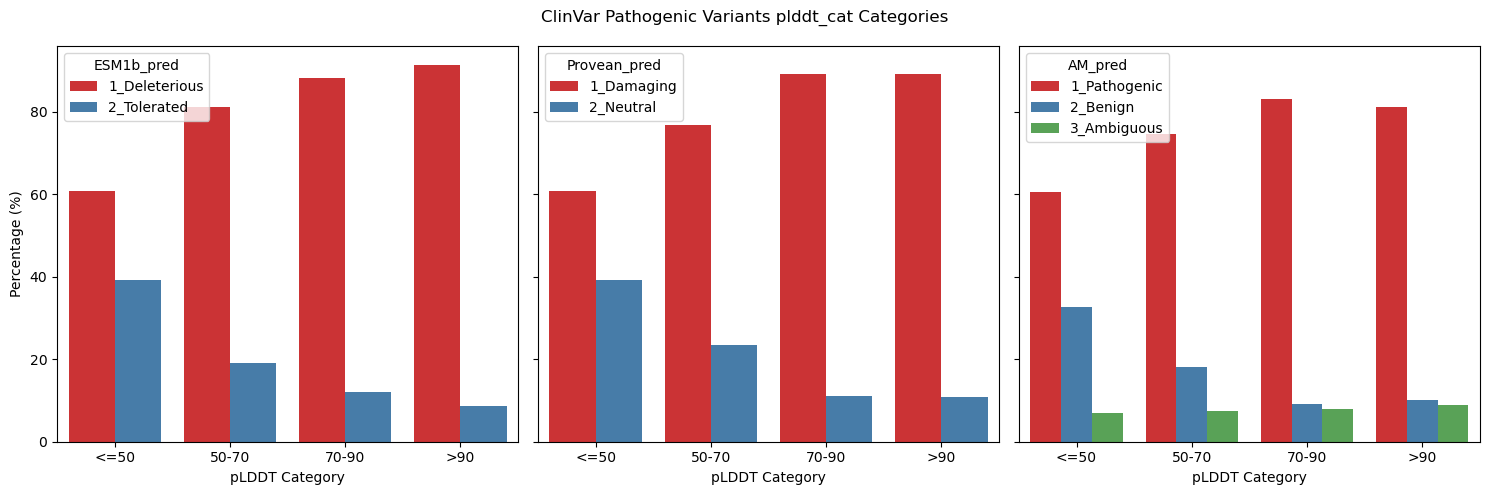

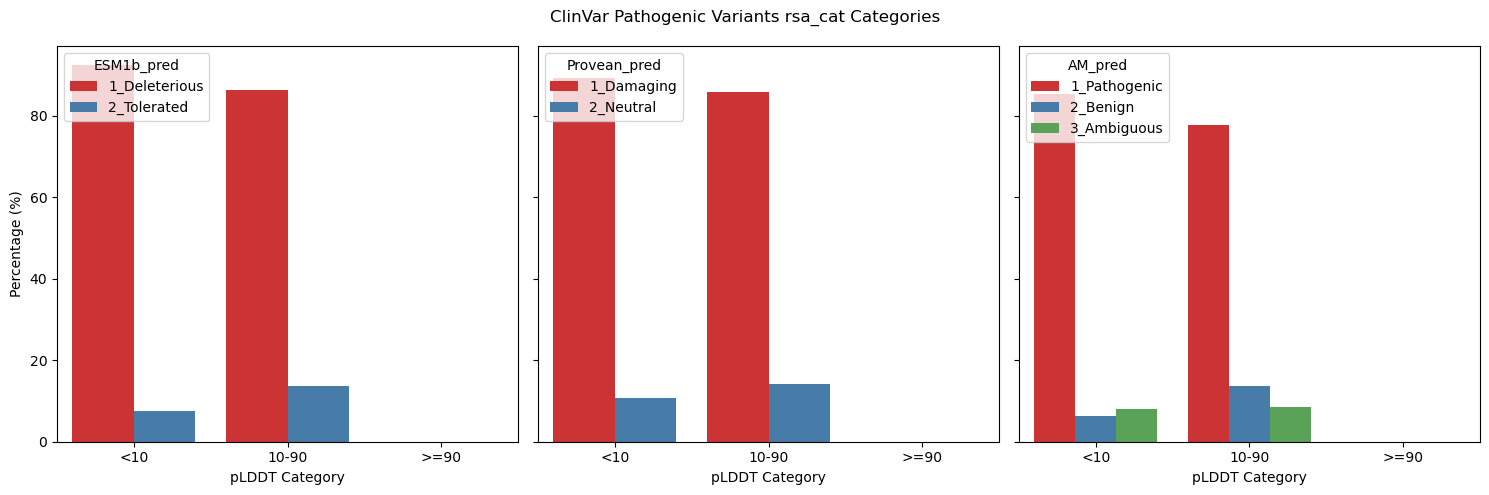

In [33]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# First, calculate the percentages for each group
# Group by both categories and calculate the percentage of each alphamissense_pred within each group

pred_cat = {
    # Make sure the categories are in the right order
    "plddt_cat": ["<=50", "50-70", "70-90", ">90"],
    "rsa_cat": ["<10", "10-90", ">=90"]
}
preds = ["ESM1b_pred", "Provean_pred", "AM_pred"]

for cat in ["plddt_cat", "rsa_cat"]:
    fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
    for pred in preds:
        percentage_df = (
            df_clinvar_w_scores
            .filter((pl.col("clinvar_clnsig_clean")=="1_Pathogenic")&(pl.col(pred)!="."))
            .group_by([cat, pred]) ##"RSA_cat", 
            .agg(count=pl.len())
            .collect()
            .to_pandas()  # Convert to pandas for easier use with seaborn
        )
        # Calculate percentage within each pLDDT_cat and RSA_cat group
        percentage_df['total'] = percentage_df.groupby([cat])['count'].transform('sum') ##, 'RSA_cat'
        percentage_df['percentage'] = percentage_df['count'] / percentage_df['total'] * 100
        
        # Filter for just this RSA category
        subset = percentage_df
        
        # Create the stacked barplot
        sns.barplot(
            x=cat, 
            y="percentage", 
            hue=pred,
            hue_order=sorted(percentage_df[pred].unique()),
            data=subset,
            order=pred_cat[cat],
            palette="Set1",  # You can choose a different color palette,
            ax=axes[preds.index(pred)]
        )
        axes[preds.index(pred)].set_xlabel("pLDDT Category")
        axes[preds.index(pred)].set_ylabel("")
        axes[preds.index(pred)].legend(loc="upper left", title=pred)

    axes[0].set_ylabel("Percentage (%)")
    # plt.legend(title="AlphaMissense Prediction")
    plt.suptitle(f"ClinVar Pathogenic Variants {cat} Categories")
    plt.tight_layout()
    plt.show()